# REBCO Quench RL Environment
## Spatially-resolved 20cm tape with QA sensors along its length

**Goal:** Train RL agent to redistribute current across multiple tapes
based on quench antenna (QA) measurements taken along the 20cm tape.

### Architecture
- **N tapes** (default 4), each divided into **S segments** along 20cm
- Each segment has independent temperature; heat diffuses between neighbors
- A **hot spot** (local disturbance) initiates in one segment of one tape
- **M QA sensors** at positions along the tape measure E-field from dI/dt
- RL agent observes QA signals, outputs current redistribution vector

### Quench timescale
Controlled by **current-sharing delay** tau_share:
- Real tapes don't instantly redistribute to Cu when I > Ic
- During delay, E = Ec x (I/Ic)^n is high, fast Joule heating
- tau_share ~ 2ms gives COMSOL-like ~25ms quench at 2xIc

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (14, 6)

---
## 1. Spatially-Resolved Single Tape

20cm tape divided into S segments. Each segment is a thermal node:

C_s * dT_s/dt = P_joule - P_cool + kappa * d2T/dx2 * A_cs

- P_joule: power-law E-J with current-sharing delay
- P_cool: surface cooling
- kappa * d2T/dx2: longitudinal heat diffusion (Cu-dominated)

The current-sharing delay models EM diffusion: f_REBCO decays
from 1.0 toward Ic/I with time constant tau_share.

In [2]:
@dataclass
class TapeParams:
    length: float = 0.20       # tape length [m]
    width: float = 12e-3       # tape width [m]
    thickness: float = 95e-6   # total thickness [m]
    Ic0: float = 234.0         # Ic at T_bath [A]
    Tc: float = 90.0           # critical temperature [K]
    T_bath: float = 77.0       # bath temperature [K]
    n_eff: float = 10.0        # power-law exponent
    Ec: float = 1e-4           # E-field criterion [V/m]
    C_vol: float = 2.0e6       # volumetric heat capacity [J/m3/K]
    kappa: float = 400.0       # thermal conductivity [W/m/K]
    h_cool: float = 0.0        # surface cooling [W/m2/K] (0=adiabatic)
    R_cu: float = 5e-4         # Cu parallel resistance per segment [Ohm]
    tau_share: float = 2e-3    # current-sharing delay [s]


class SpatialTape:
    def __init__(self, n_segments=20, params=None):
        self.p = params or TapeParams()
        self.S = n_segments
        self.dx = self.p.length / n_segments
        self.x = np.linspace(self.dx/2, self.p.length - self.dx/2, n_segments)
        self.A_cs = self.p.width * self.p.thickness
        self.C_seg = self.p.C_vol * self.A_cs * self.dx
        self.A_cool = 2 * self.p.width * self.dx
        self.T = np.full(n_segments, self.p.T_bath)
        self.f_rebco = np.ones(n_segments)

    def Ic(self, T):
        T = np.asarray(T)
        return self.p.Ic0 * np.clip((self.p.Tc - T) / (self.p.Tc - self.p.T_bath), 0, 1)

    def step(self, I, dt):
        T, f = self.T, self.f_rebco
        # Current-sharing relaxation
        f_ss = np.clip(self.Ic(T) / max(abs(I), 1e-10), 0, 1)
        alpha = min(dt / self.p.tau_share, 1.0) if self.p.tau_share > 0 else 1.0
        f = f + (f_ss - f) * alpha
        # E-field per segment
        Ic_arr = self.Ic(T)
        ratio = np.abs(I) * f / np.maximum(Ic_arr, 1e-10)
        E = np.minimum(self.p.Ec * np.power(np.maximum(ratio, 1e-20), self.p.n_eff), 1e3)
        above_Tc = Ic_arr < 1.0
        E[above_Tc] = np.abs(I) * self.p.R_cu / self.dx
        # Dissipation
        P_rebco = E * np.abs(I) * f * self.dx
        P_cu = (np.abs(I) * (1 - f))**2 * self.p.R_cu
        P_total = P_rebco + P_cu
        P_cool = self.p.h_cool * self.A_cool * (T - self.p.T_bath)
        # Thermal diffusion
        d2T = np.zeros(self.S)
        d2T[1:-1] = (T[:-2] - 2*T[1:-1] + T[2:]) / self.dx**2
        d2T[0] = (T[1] - T[0]) / self.dx**2
        d2T[-1] = (T[-2] - T[-1]) / self.dx**2
        P_diff = self.p.kappa * self.A_cs * d2T * self.dx
        # Update
        self.T = np.maximum(T + (P_total - P_cool + P_diff) / self.C_seg * dt, self.p.T_bath)
        self.f_rebco = f
        return {"E": E, "V_seg": E * self.dx, "V_total": np.sum(E * self.dx),
                "T": self.T.copy(), "f_rebco": f.copy()}

    def E_field(self, I, T, f_rebco):
        """E-field per segment [V/m]. Public method for observation."""
        Ic_arr = self.Ic(T)
        ratio = np.abs(I) * f_rebco / np.maximum(Ic_arr, 1e-10)
        E = np.minimum(self.p.Ec * np.power(np.maximum(ratio, 1e-20), self.p.n_eff), 1e3)
        above_Tc = Ic_arr < 1.0
        E[above_Tc] = np.abs(I) * self.p.R_cu / self.dx
        return E

    def apply_disturbance(self, x_center, width_m, delta_T):
        self.T += delta_T * np.exp(-0.5 * ((self.x - x_center) / width_m)**2)

### Check: quench propagation along 20cm tape

Quench at t = 12.6 ms


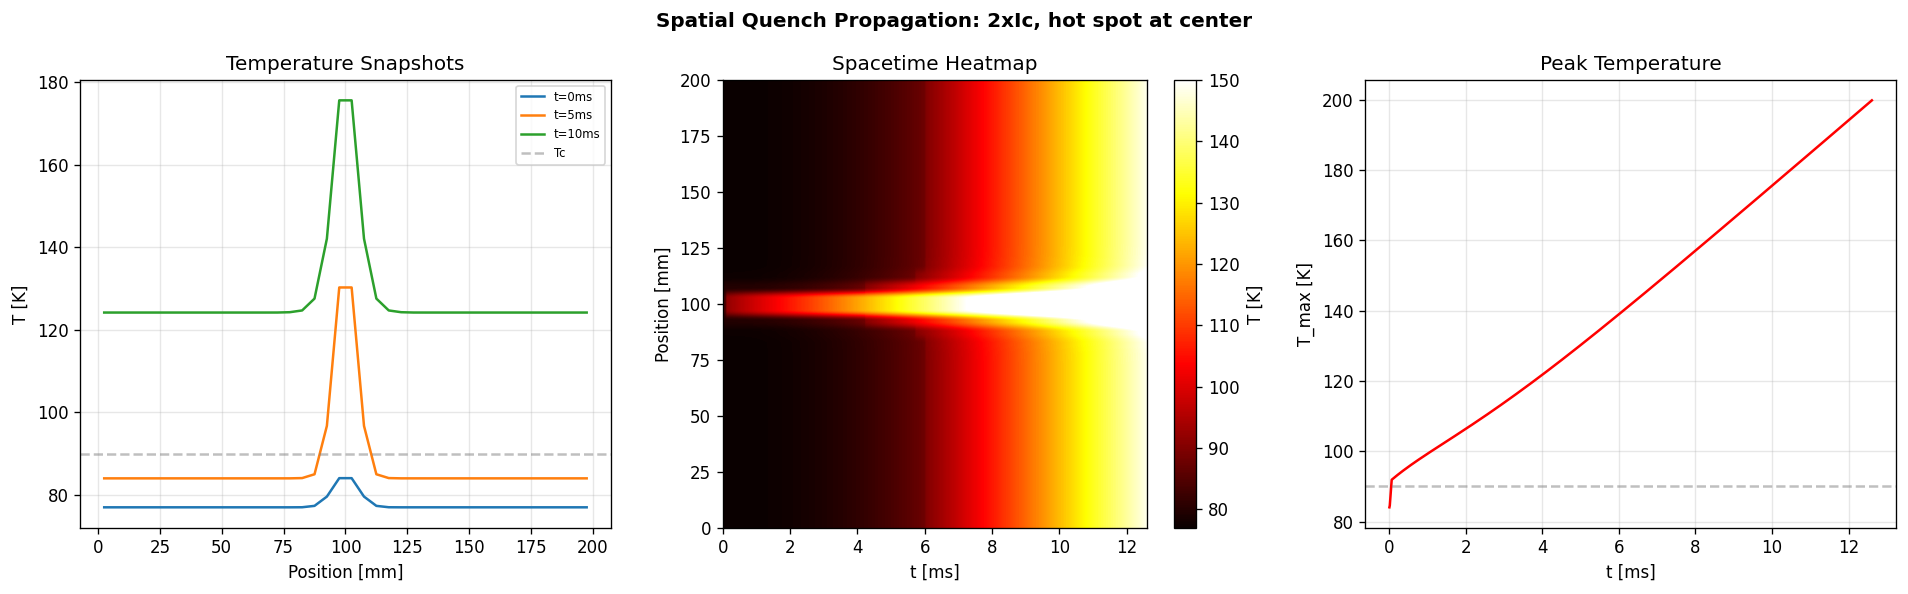

In [4]:
tape = SpatialTape(n_segments=40)
tape.apply_disturbance(x_center=0.10, width_m=0.005, delta_T=8.0)

I = 2.0 * tape.p.Ic0
dt = 1e-5

snap_times = [0, 5, 10, 15, 20, 30]
snapshots = {0: tape.T.copy()}
T_map = [tape.T.copy()]
t_map = [0]

for step in range(5000):
    tape.step(I, dt)
    t_ms = (step+1) * dt * 1e3
    if step % 5 == 0:
        T_map.append(tape.T.copy())
        t_map.append(t_ms)
    for st in snap_times:
        if st not in snapshots or snapshots[st] is None:
            if t_ms >= st:
                snapshots[st] = tape.T.copy()
    if np.max(tape.T) > 200:
        print(f"Quench at t = {t_ms:.1f} ms")
        break

T_map = np.array(T_map)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Spatial Quench Propagation: 2xIc, hot spot at center", fontweight="bold")

x_mm = tape.x * 1e3
for st in snap_times:
    if snapshots.get(st) is not None:
        axes[0].plot(x_mm, snapshots[st], label=f"t={st}ms")
axes[0].axhline(90, color="gray", ls="--", alpha=0.5, label="Tc")
axes[0].set_xlabel("Position [mm]"); axes[0].set_ylabel("T [K]")
axes[0].set_title("Temperature Snapshots"); axes[0].legend(fontsize=7); axes[0].grid(True, alpha=0.3)

im = axes[1].imshow(T_map.T, aspect="auto", origin="lower",
    extent=[0, t_map[-1], 0, 200], cmap="hot", vmin=77, vmax=min(150, T_map.max()))
plt.colorbar(im, ax=axes[1], label="T [K]")
axes[1].set_xlabel("t [ms]"); axes[1].set_ylabel("Position [mm]")
axes[1].set_title("Spacetime Heatmap")

axes[2].plot(t_map, [np.max(T_map[i]) for i in range(len(t_map))], "r-", lw=1.5)
axes[2].axhline(90, color="gray", ls="--", alpha=0.5)
axes[2].set_xlabel("t [ms]"); axes[2].set_ylabel("T_max [K]"); axes[2].set_title("Peak Temperature")
axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 2. QA Sensors Along the Tape

QA sensors at positions z_k along the tape measure the E-field disturbance
from current redistribution in nearby segments:

signal_k = sum_s mu0/(2pi) * |dI_rebco,s / dt| / sqrt((z_k - x_s)^2 + r_offset^2)

- Segments near the quench have large |dI/dt| (current leaving REBCO)
- Nearby QA sensors see strong signal, distant sensors see weak/delayed signal
- The spatial QA pattern encodes: location, velocity, severity of quench

In [5]:
class QAArray:
    """QA sensors along the tape measuring E-field disturbance."""
    def __init__(self, n_sensors=8, tape_length=0.20, r_offset=0.01, positions=None):
        self.z = np.asarray(positions) if positions is not None else np.linspace(0, tape_length, n_sensors + 2)[1:-1]
        self.n = len(self.z)
        self.r_offset = r_offset

    def measure(self, tape, I, dt):
        """
        QA signal at each sensor position.
        
        Each sensor picks up the E-field weighted by 1/distance from each segment.
        This is what a real QA coil measures: the local E-field disturbance
        from resistive zones in the tape.
        
        signal_k = sum_s E_s / sqrt((z_k - x_s)^2 + r_offset^2)
        
        Segments with high E (where I > Ic, current sharing active) produce
        strong signal at nearby sensors. Cold segments contribute nothing.
        """
        # Get E-field per segment (this is the actual measurable quantity)
        E = tape.E_field(I, tape.T, tape.f_rebco)  # shape (S,)
        
        # Distance from each sensor to each segment
        dist = np.sqrt((self.z[:, None] - tape.x[None, :])**2 + self.r_offset**2)
        
        # Weighted pickup: nearby segments contribute more
        signals = np.sum(E[None, :] * tape.dx / dist, axis=1)
        
        return signals

    def reset(self):
        pass

### Check: QA signals during quench (hot spot at x=120mm)

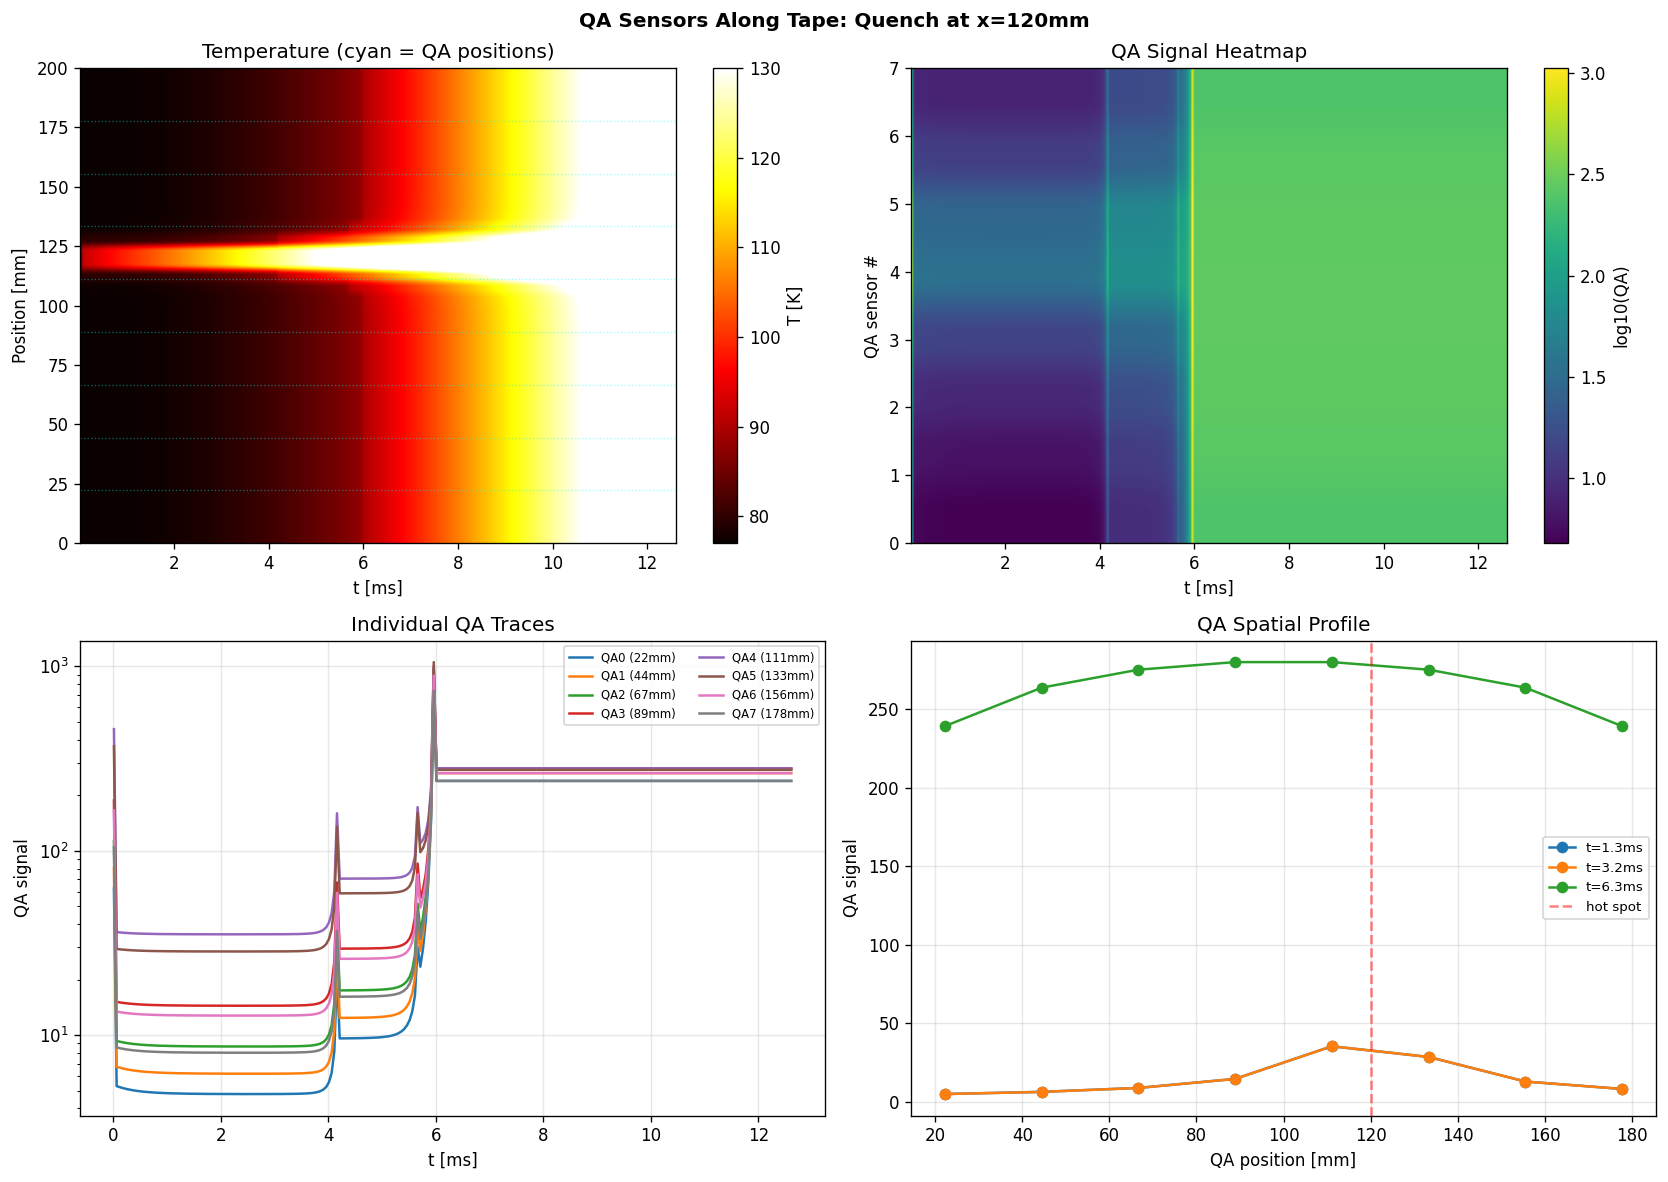

In [6]:
tape = SpatialTape(n_segments=40, params=TapeParams(h_cool=0.0))
qa = QAArray(n_sensors=8, tape_length=0.20, r_offset=0.01)
tape.apply_disturbance(x_center=0.12, width_m=0.005, delta_T=8.0)

I = 2.0 * tape.p.Ic0; dt = 1e-5
qa_hist, T_hist, t_arr = [], [], []

for step in range(4000):
    tape.step(I, dt)
    sig = qa.measure(tape, I, dt)
    if step % 5 == 0:
        qa_hist.append(sig.copy()); T_hist.append(tape.T.copy())
        t_arr.append((step+1)*dt*1e3)
    if np.max(tape.T) > 200: break

qa_hist = np.array(qa_hist); T_hist = np.array(T_hist); t_arr = np.array(t_arr)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("QA Sensors Along Tape: Quench at x=120mm", fontweight="bold")

im = axes[0,0].imshow(T_hist.T, aspect="auto", origin="lower",
    extent=[t_arr[0], t_arr[-1], 0, 200], cmap="hot", vmin=77, vmax=min(130, T_hist.max()))
plt.colorbar(im, ax=axes[0,0], label="T [K]")
for z in qa.z: axes[0,0].axhline(z*1e3, color="cyan", ls=":", alpha=0.4, lw=0.8)
axes[0,0].set_xlabel("t [ms]"); axes[0,0].set_ylabel("Position [mm]")
axes[0,0].set_title("Temperature (cyan = QA positions)")

im2 = axes[0,1].imshow(np.log10(np.maximum(qa_hist, 1e-15)).T, aspect="auto", origin="lower",
    extent=[t_arr[0], t_arr[-1], 0, qa.n-1], cmap="viridis")
plt.colorbar(im2, ax=axes[0,1], label="log10(QA)")
axes[0,1].set_xlabel("t [ms]"); axes[0,1].set_ylabel("QA sensor #")
axes[0,1].set_title("QA Signal Heatmap")

for i in range(qa.n):
    axes[1,0].semilogy(t_arr, np.maximum(qa_hist[:, i], 1e-15),
        label=f"QA{i} ({qa.z[i]*1e3:.0f}mm)")
axes[1,0].set_xlabel("t [ms]"); axes[1,0].set_ylabel("QA signal")
axes[1,0].set_title("Individual QA Traces"); axes[1,0].legend(fontsize=7, ncol=2)
axes[1,0].grid(True, alpha=0.3)

for t_idx in [len(t_arr)//10, len(t_arr)//4, len(t_arr)//2, -1]:
    if 0 <= t_idx < len(t_arr):
        axes[1,1].plot(qa.z*1e3, qa_hist[t_idx], "o-", label=f"t={t_arr[t_idx]:.1f}ms")
axes[1,1].axvline(120, color="red", ls="--", alpha=0.5, label="hot spot")
axes[1,1].set_xlabel("QA position [mm]"); axes[1,1].set_ylabel("QA signal")
axes[1,1].set_title("QA Spatial Profile"); axes[1,1].legend(fontsize=8)
axes[1,1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 3. Multi-Tape Cable Environment

N tapes (each spatially resolved) + QA sensors. RL interface:
- **Obs:** combined QA signals + per-tape voltage + per-tape T_max
- **Action:** current fractions per tape (softmax-normalized)
- **Reward:** survival + margin bonus - quench penalty

In [7]:
class MultiTapeCableEnv:
    def __init__(self, n_tapes=4, n_segments=20, n_qa=8,
                 I_total_frac=1.5, dt=1e-5, max_steps=5000,
                 tape_params=None, qa_r_offset=0.01,
                 disturb_T_range=(8.0, 12.0), disturb_width_range=(0.003, 0.01)):
        self.n_tapes, self.n_qa, self.dt, self.max_steps = n_tapes, n_qa, dt, max_steps
        self.disturb_T_range, self.disturb_width_range = disturb_T_range, disturb_width_range
        tp = tape_params or TapeParams(h_cool=0.0)
        self.tapes = [SpatialTape(n_segments, tp) for _ in range(n_tapes)]
        self.qas = [QAArray(n_qa, tp.length, qa_r_offset) for _ in range(n_tapes)]
        self.Ic0, self.Tc = tp.Ic0, tp.Tc
        self.I_total = I_total_frac * self.Ic0 * n_tapes  # frac is PER TAPE
        self._I = np.full(n_tapes, self.I_total / n_tapes)
        self._step_count = 0
        self._disturbed = 0; self._disturb_x = 0.1

    def reset(self, seed=None):
        if seed is not None: np.random.seed(seed)
        tp = self.tapes[0].p
        for tape in self.tapes: tape.T[:] = tp.T_bath; tape.f_rebco[:] = 1.0
        for qa in self.qas: qa.reset()
        self._disturbed = np.random.randint(self.n_tapes)
        self._disturb_x = np.random.uniform(0.02, tp.length - 0.02)
        dT = np.random.uniform(*self.disturb_T_range)
        dw = np.random.uniform(*self.disturb_width_range)
        self.tapes[self._disturbed].apply_disturbance(self._disturb_x, dw, dT)
        self._I = np.full(self.n_tapes, self.I_total / self.n_tapes)
        self._step_count = 0
        return self._obs()

    def _obs(self):
        qa_total = np.zeros(self.n_qa)
        for i in range(self.n_tapes):
            qa_total += self.qas[i].measure(self.tapes[i], self._I[i], self.dt)
        qa_n = np.log10(np.maximum(qa_total, 1e-15)) / 10 + 1.5
        V = np.array([np.sum(t.E_field(self._I[i], t.T, t.f_rebco) * t.dx) for i, t in enumerate(self.tapes)])
        V_n = np.log10(np.maximum(V, 1e-15)) / 10 + 1.5
        Tm = np.array([np.max(t.T) for t in self.tapes])
        return np.concatenate([qa_n, V_n, (Tm - 77) / 13]).astype(np.float32)

    def step(self, action):
        action = np.asarray(action, dtype=float).ravel()
        exp_a = np.exp(action - np.max(action))
        self._I = (exp_a / exp_a.sum()) * self.I_total
        for i in range(self.n_tapes): self.tapes[i].step(self._I[i], self.dt)
        self._step_count += 1
        Tm = [np.max(t.T) for t in self.tapes]
        quenched = any(t > self.Tc + 30 for t in Tm)
        truncated = self._step_count >= self.max_steps
        reward = -100.0 if quenched else 1.0 + sum(max(self.Tc-t, 0)/13 for t in Tm) - 0.2*np.std(Tm)
        info = {"T_max": Tm, "I": self._I.copy(), "quenched": quenched,
                "disturbed_tape": self._disturbed, "disturb_x": self._disturb_x}
        return self._obs(), reward, quenched, truncated, info

### Demo: 4-tape cable, equal split vs reactive policy

Equal:    860 steps, quench=True, T_max=['82.8', '82.8', '120.0', '82.8']
Reactive: 1644 steps, quench=True, T_max=['120.0', '120.0', '120.0', '120.0']
Disturbed: tape 2 at x=147mm


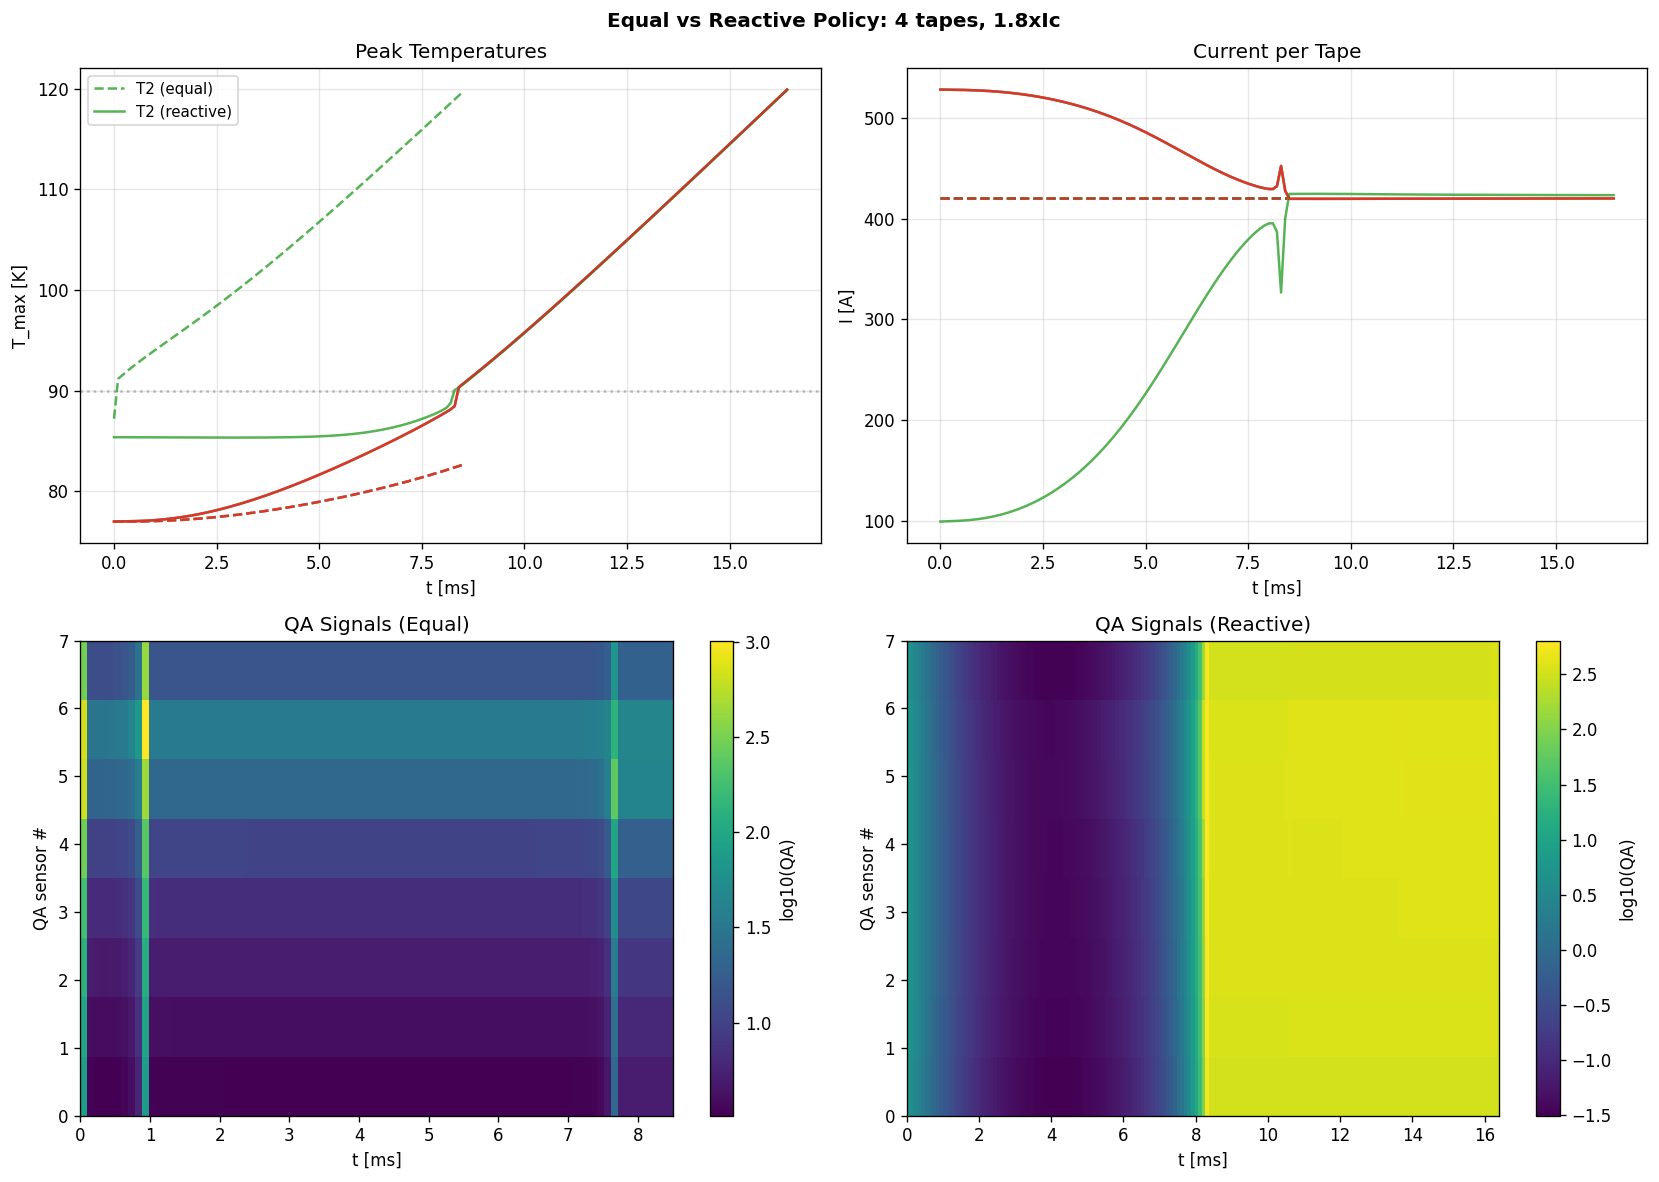

In [8]:
def run_episode(n_tapes=4, n_qa=8, I_frac=1.8, policy="equal", seed=42, max_steps=4000):
    env = MultiTapeCableEnv(n_tapes=n_tapes, n_segments=20, n_qa=n_qa,
                            I_total_frac=I_frac, dt=1e-5, max_steps=max_steps)
    obs = env.reset(seed=seed)
    hist = {"T_max": [], "qa": [], "time": [], "I": []}
    for step in range(max_steps):
        if policy == "equal":
            action = np.zeros(n_tapes)
        else:
            # Reactive: penalize tapes with high T_max
            Tm = np.array([np.max(t.T) for t in env.tapes])
            action = -(Tm - 77) / 5  # hot tapes get negative -> less current
        obs, reward, term, trunc, info = env.step(action)
        if step % 10 == 0:
            qa_sig = np.zeros(n_qa)
            for i in range(n_tapes): qa_sig += env.qas[i].measure(env.tapes[i], env._I[i], env.dt)
            hist["T_max"].append(list(info["T_max"])); hist["qa"].append(qa_sig)
            hist["time"].append(step*env.dt*1e3); hist["I"].append(info["I"])
        if term or trunc: break
    for k in hist: hist[k] = np.array(hist[k])
    hist["info"] = info; hist["steps"] = step+1
    hist["disturbed"] = env._disturbed; hist["disturb_x"] = env._disturb_x
    return hist

h_eq = run_episode(policy="equal", seed=42)
h_re = run_episode(policy="reactive", seed=42)
print(f"Equal:    {h_eq['steps']} steps, quench={h_eq['info']['quenched']}, T_max={[f'{t:.1f}' for t in h_eq['info']['T_max']]}")
print(f"Reactive: {h_re['steps']} steps, quench={h_re['info']['quenched']}, T_max={[f'{t:.1f}' for t in h_re['info']['T_max']]}")
print(f"Disturbed: tape {h_eq['disturbed']} at x={h_eq['disturb_x']*1e3:.0f}mm")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Equal vs Reactive Policy: 4 tapes, 1.8xIc", fontweight="bold")
for label, h, ls in [("equal", h_eq, "--"), ("reactive", h_re, "-")]:
    t = h["time"]
    for i in range(4):
        axes[0,0].plot(t, h["T_max"][:, i], ls=ls, color=f"C{i}",
            label=f"T{i} ({label})" if i == h["disturbed"] else None, alpha=0.8)
    for i in range(4):
        axes[0,1].plot(t, h["I"][:, i], ls=ls, color=f"C{i}", alpha=0.8)
axes[0,0].axhline(90, color="gray", ls=":", alpha=0.5)
axes[0,0].set_xlabel("t [ms]"); axes[0,0].set_ylabel("T_max [K]"); axes[0,0].set_title("Peak Temperatures")
axes[0,0].legend(fontsize=9); axes[0,0].grid(True, alpha=0.3)
axes[0,1].set_xlabel("t [ms]"); axes[0,1].set_ylabel("I [A]"); axes[0,1].set_title("Current per Tape")
axes[0,1].grid(True, alpha=0.3)

# QA heatmaps
for ax, h, label in [(axes[1,0], h_eq, "Equal"), (axes[1,1], h_re, "Reactive")]:
    im = ax.imshow(np.log10(np.maximum(h["qa"], 1e-15)).T, aspect="auto", origin="lower",
        extent=[h["time"][0], h["time"][-1], 0, 7], cmap="viridis")
    plt.colorbar(im, ax=ax, label="log10(QA)")
    ax.set_xlabel("t [ms]"); ax.set_ylabel("QA sensor #"); ax.set_title(f"QA Signals ({label})")
plt.tight_layout(); plt.show()

---
## Summary

**What we built:**
1. Spatially-resolved tape (20cm, N segments) with thermal diffusion + current-sharing delay
2. QA sensor array along the tape -- each sensor measures 1/r pickup from dI/dt
3. Multi-tape cable RL environment (Gymnasium-compatible)
4. Reactive policy demo showing QA-informed redistribution

**What the spatial QA pattern tells the RL agent:**
- **Where** the quench started (sensors nearest the hot spot respond first)
- **How fast** it propagates (signal wavefront across sensor array)
- **Which tape** (cross-tape signal coupling)
- **How severe** (magnitude ~ dI/dt ~ overcurrent)

**Next steps:** train surrogate (QA -> state), then RL controller (PPO/SAC on CableEnv).